In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.mass_detect.scripts.cohort import select_cohort
from src.mass_detect.scripts.config import CENTRE_INDEX, LIDC_MANIFEST_FILE, LNDB_MANIFEST_FILE, PATCHES_DIR, ROI_DIR, SPACING_MM
from src.mass_detect.scripts.config import READINGS_FILE, ROI_RADIOMICS_FILE
from src.mass_detect.scripts.config import FEATURE_REPORT_FILE, MODEL_FEATURES_FILE, READING_FEATURES_FILE
from src.mass_detect.scripts.feature_tables import feature_inventory, label_free_filter, model_tables, volume_check
from src.mass_detect.scripts.rois import build_readings, build_rois, roi_quality
from src.mass_detect.scripts.rois import add_roi_diameters, extract_roi_radiomics, radiomic_columns, reader_icc
from src.mass_detect.scripts.sensitivity import RESULTS_DIR, cube_extents, cube_fit_table
from src.mass_detect.scripts.run_voxel_sensitivity import run as run_voxel_sensitivity

pd.set_option("display.width", 140)

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Features from the Radiologists' Regions
  </h1>
  <p>
  Every nodule of the cohort is described by PyRadiomics features measured inside the region that its radiologists drew. Every nodule in training and validation comes with that region, so we measure the nodule where the experts saw it. Three reasons led to this choice:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The same code measures both datasets. LNDb and LIDC IDRI record the size of a nodule with different tools, so their own numbers are not directly comparable. Computing everything ourselves from the masks gives one definition for all nodules.</li>
    <li style="margin-bottom: 8px;">The region is where radiomics makes sense. The IBSI defines its features inside a region of interest (Zwanenburg et al., 2020), and features computed on the regions of two radiologists agree closely with each other, as the robustness section shows.</li>
    <li style="margin-bottom: 8px;">The diameter, the single most important sign for the radiologist (MacMahon et al., 2017), comes out of the same region and is measured the same way in both datasets.</li>
  </ul>
  <p>
  This notebook loads the cohort, collects every reading, cuts the masks on the grid of the patches, extracts the PyRadiomics features, checks which features stay stable when another radiologist draws the contour, keeps the features that are present, stable and not redundant, and saves the tables that notebook 06 reads. It ends with the checks of the geometry of the patch (cube size and voxel size). The functions live in <strong>src/mass_detect/scripts/rois.py</strong>, <strong>feature_tables.py</strong> and <strong>sensitivity.py</strong>.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics with an IBSI oriented configuration
  </h3>
  <p>
  PyRadiomics is a library which helps calculate hundreds of features of the images inside a desired region. Configuration (IBSI: Zwanenburg et al., 2020; PyRadiomics: van Griethuysen et al., 2017):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Isotropic 0.6 mm voxels with linear interpolation: already done when the patch is cut, so PyRadiomics does not resample again. Texture features depend on voxel size (Shafiq-ul-Hassan et al., 2017). The IBSI asks for isotropic voxels but does not fix their size therefore we tested with different possibile values; 0.6 mm was chosen with the sensitivity analysis at the end of this notebook.</li>
    <li style="margin-bottom: 8px;">Intensity range [-1024, 3071] HU before discretisation. These are the possible values since they are the range of values that a TAC of 12 bits can have. We chose to ensure all the values were inside this range since if other values occur it probably means they are not tissues and may be metal for instance.</li>
    <li style="margin-bottom: 8px;">Fixed bin width of 25 HU. For calibrated units such as HU the IBSI recommends a fixed bin size, so that a bin means the same density in every scan; 25 HU is the PyRadiomics default and widely used in CT.</li>
    <li style="margin-bottom: 8px;">Feature classes: first order, shape, GLCM, GLRLM, GLSZM, GLDM and NGTDM, on the original image and on Laplacian of Gaussian filtered images with sigma 1, 2 and 3 mm (edges and blobs at the scales of small nodules). PyRadiomics documents where its definitions deviate from the IBSI.</li>
    <li style="margin-bottom: 8px;">Region of interest: the consensus of the radiologists' masks, which describes the nodule, and each reader's own mask, used to measure robustness and to train on single readings.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   ICC: what does it measure?
  </h3>

  <p>
    Two radiologists never draw exactly the same contour, so a feature computed from each of their masks will differ a little on the same nodule. The intraclass correlation coefficient (ICC) asks whether that difference is small compared with the differences between nodules: it is the share of the total variability that comes from real differences between nodules rather than from who drew the contour. An ICC of 1 means the two radiologists give the same value for every nodule; an ICC of 0 means the disagreement between them is as large as the differences between nodules, so the feature describes the contour more than the nodule.   
  </p>
  <p>
    We use ICC(2,1) (Shrout and Fleiss, 1979): absolute agreement, so that a systematic difference (one radiologist always drawing larger contours) also lowers the score, unlike a plain correlation; random raters, because the feature should hold for any radiologist and not only for these five; and a single rater, because the model uses one mask per nodule. Following Koo and Li (2016), we call a feature robust when its ICC is at least 0.75.
  </p>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The study cohort
  </h3>
  <p>
    The nodules of the study are selected in notebook 03: nodules with a malignancy rating and a radiologist mask (3 mm or more), from LIDC IDRI groups of at most four annotations with a confirmed position. There are 3237 of them, from 1062 patients: 622 from LNDb and 2615 from LIDC IDRI. Their label is the mean rating rounded half up, on the 1 to 5 scale and on the derived 1 to 3 scale.
  </p>
</div>

In [2]:
# The study cohort of notebook 03 (src/mass_detect/scripts/cohort.py)
cohort, funnel = select_cohort()
print(f"{len(cohort)} nodules from {cohort.patient_id.nunique()} patients")

3237 nodules from 1062 patients


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   One row per reading
  </h3>
  <p>
  A reading is one radiologist's view of one nodule: the contour that radiologist drew and the rating that radiologist gave. We keep every reading, because the next notebook compares two ways of training: on the mean rating of each nodule, and on each reading separately. Learning from every annotator instead of only from their average is a known way to use labels from several experts who disagree (Raykar et al., 2010).
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">In LNDb each reader has one mask file per CT, in which every finding is drawn with its own number. The merged file of the dataset tells which reader and which number belong to each nodule.</li>
    <li style="margin-bottom: 8px;">In LIDC IDRI each pylidc annotation is one reading. The dataset does not say which of the four radiologists drew it, so the annotation number stands for the reader.</li>
  </ul>

  The unit of analysis stays the nodule: readings are used to measure how robust the features are between readers, and as one training option in which each reading weighs one divided by the number of readers, so every nodule weighs the same. 
</div>

In [3]:
# One row per reading (src/mass_detect/scripts/rois.py): built once, then read from disk
if READINGS_FILE.exists():
    readings = pd.read_csv(READINGS_FILE)
else:
    readings = build_readings(cohort)

# Readings and readers per nodule, in each dataset
readers = readings.groupby(["dataset", "nodule_uid"]).size().rename("readers")
summary = pd.DataFrame({
    "readings": readings.groupby("dataset").size(),
    "nodules": readings.groupby("dataset")["nodule_uid"].nunique(),
    "mean readers per nodule": readers.groupby("dataset").mean().round(2),
})
nodules_per_count = readers.groupby("dataset").value_counts().unstack().add_prefix("nodules with readers = ")
summary.join(nodules_per_count)

,readings,nodules,mean readers per nodule,nodules with readers = 1,nodules with readers = 2,nodules with readers = 3,nodules with readers = 4
dataset,,,,,,,
LIDC,6700,2615,2.56,772.0,481.0,482.0,880.0
LNDb,885,622,1.42,403.0,175.0,44.0,NaN


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The masks, on the grid of the patch
  </h3>
  <p>
  Every mask is cut exactly like its CT patch: a cube of 64 mm with 0.6 mm voxels (107 per side) around the same centre, so that mask and patch overlap voxel by voxel. Masks use nearest neighbour interpolation, which keeps them made of whole voxels instead of blurring their border.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">LNDb: the region of a reader is the set of voxels that carry that finding's number in the reader's mask file.</li>
    <li style="margin-bottom: 8px;">LIDC IDRI: pylidc turns the contours of an annotation into a mask inside its bounding box, and we place that box in the CT with the geometry that SimpleITK reads from the DICOM files, the same geometry used to cut the patches.</li>
    <li style="margin-bottom: 8px;">Consensus: a voxel belongs to the consensus region when at least half of the readers drew it, the definition used by pylidc. With one reader the consensus is that reader's mask, and with two readers it is their union.</li>
  </ul>
  <p>
  The checks that follow come from a checklist of what a correct mask looks like: it holds only 0 and 1, it lies on the same grid as its CT patch, the consensus is not empty, and its centre of mass is close to the centre of the patch. A mask placed in the wrong spot would have its centre far from the centre of the patch, and a lost contour would leave the mask empty.
  </p>
</div>

In [4]:
# Masks of every reading and the consensus, one file per nodule (src/mass_detect/scripts/rois.py)
if len(list(ROI_DIR.glob("*.npz"))) < len(cohort):
    build_rois(cohort, readings)

# The checklist of every mask, then one line per dataset
quality = roi_quality(cohort)
quality["empty_consensus"] = quality["consensus_voxels"] == 0
quality["not_binary"] = ~quality["binary"]
quality["off_the_grid"] = ~quality["shape_ok"]
quality.groupby("dataset").agg(
    nodules=("patch_id", "size"),
    empty_reader_masks=("empty_reader_masks", "sum"),
    empty_consensus=("empty_consensus", "sum"),
    masks_not_binary=("not_binary", "sum"),
    masks_off_the_patch_grid=("off_the_grid", "sum"),
    smallest_consensus_voxels=("consensus_voxels", "min"),
    median_consensus_voxels=("consensus_voxels", "median"),
    median_offset_mm=("centre_offset_mm", "median"),
    p99_offset_mm=("centre_offset_mm", lambda offset: offset.quantile(0.99)),
    max_offset_mm=("centre_offset_mm", "max"),
).round(2)

,nodules,empty_reader_masks,empty_consensus,masks_not_binary,masks_off_the_patch_grid,smallest_consensus_voxels,median_consensus_voxels,median_offset_mm,p99_offset_mm,max_offset_mm
dataset,,,,,,,,,,
LIDC,2615,0,0,0,0,19,460.0,0.27,1.48,4.08
LNDb,622,3,0,0,0,41,317.5,0.37,0.80,1.04


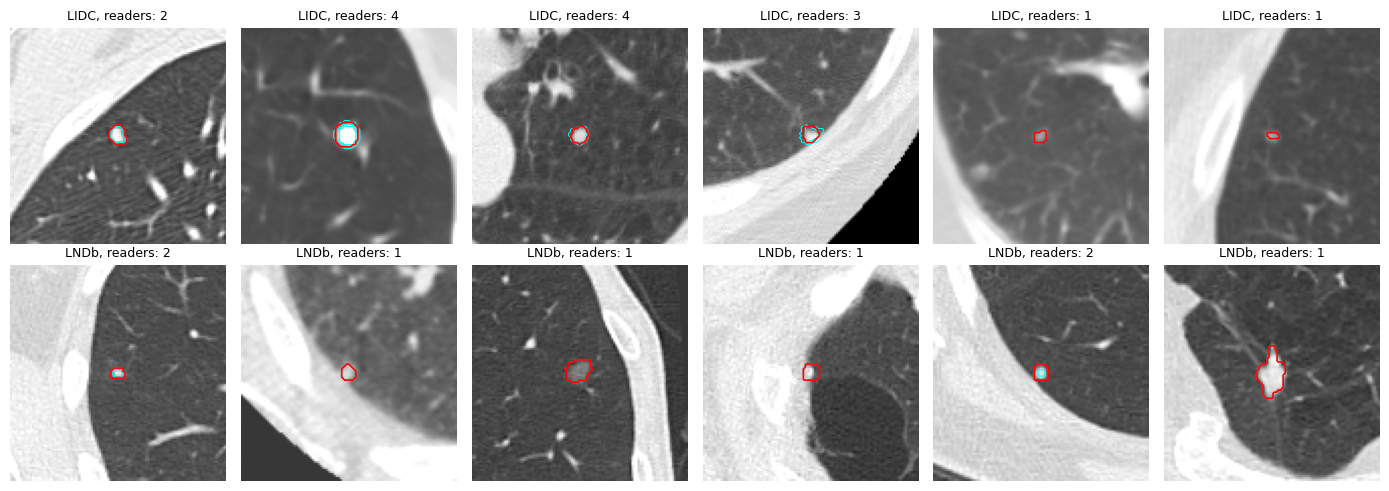

In [5]:
# Six random nodules per dataset: central axial slice, consensus in red and each reader in cyan
manifest = pd.concat([pd.read_csv(LNDB_MANIFEST_FILE), pd.read_csv(LIDC_MANIFEST_FILE)])
file_of = dict(zip(manifest["patch_id"], manifest["file"]))
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row_axes, (dataset, group) in zip(axes, cohort.groupby("dataset")):
    for axis, patch_id in zip(row_axes, rng.choice(group["patch_id"], 6, replace=False)):
        patch = np.load(PATCHES_DIR / file_of[patch_id])
        rois = np.load(ROI_DIR / f"{patch_id}.npz")
        axis.imshow(patch[CENTRE_INDEX], cmap="gray", vmin=-1350, vmax=150)      # lung window
        for mask in rois["masks"]:
            axis.contour(mask[CENTRE_INDEX], levels=[0.5], colors="cyan", linewidths=0.7)
        axis.contour(rois["consensus"][CENTRE_INDEX], levels=[0.5], colors="red", linewidths=1.2)
        axis.set_title(f"{dataset}, readers: {len(rois['readers'])}", fontsize=9)
        axis.axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Every mask passes the checklist: no consensus region is empty, and every mask holds only 0 and 1 and lies on the grid of its patch. The centre of the consensus region lies at a median of 0.27 mm from the centre of the patch in LIDC IDRI and 0.37 mm in LNDb, and 99% of the nodules are within 1.5 mm. The few nodules a little further away (at most 4.1 mm) are large LIDC IDRI nodules, whose irregular shape moves their centre of mass away from the marked centre. Only 3 of the 7585 reader masks are empty, all in LNDb; their nodules keep the consensus region of their other readers.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics on every region
  </h3>
  <p>
  We use the same IBSI oriented configuration described above: 0.6 mm isotropic voxels, intensities limited to [-1024, 3071] HU, a fixed bin width of 25 HU, and every feature class on the original image and on Laplacian of Gaussian images with sigma 1, 2 and 3 mm. Features are extracted from the consensus region of every nodule, which describes the nodule, and from every reader's region, which is needed to measure robustness and to train on single readings.
  </p>
  <p>
  The diameter comes from the shape features of the same region. We keep two versions: the diameter of the sphere with the same volume as the region, and the longest diameter in an axial slice, which is how the Fleischner Society recommends measuring nodules on CT (Bankier et al., 2017). Regions smaller than 8 voxels are too small for texture and get no features.
  </p>
</div>

In [6]:
# PyRadiomics on every region (about an hour with 10 processes at 0.6 mm), then read from disk
if ROI_RADIOMICS_FILE.exists():
    features = pd.read_csv(ROI_RADIOMICS_FILE)
else:
    features = extract_roi_radiomics(cohort)
features = add_roi_diameters(features)
names = radiomic_columns(features)

# The consensus regions, with the information of their nodule
consensus = features[features["roi"] == "consensus"]
consensus = consensus.merge(cohort[["patch_id", "dataset", "diameter_mm", "rating"]], on="patch_id")
reader_regions = features[features["roi"] != "consensus"]
print(f"{len(features)} regions ({len(consensus)} consensus and {len(reader_regions)} reader regions), "
      f"{len(names)} PyRadiomics features each")

# Regions under 8 voxels get no features
print("consensus regions without features:", int(consensus[names[0]].isna().sum()))
print("reader regions without features:", int(reader_regions[names[0]].isna().sum()))

10822 regions (3237 consensus and 7585 reader regions), 386 PyRadiomics features each
consensus regions without features: 0
reader regions without features: 8


In [7]:
# The voxel size reached PyRadiomics if its volume equals the voxels of the mask times the volume of one voxel
check = volume_check(consensus, quality)
ratio = check["ratio"]
print(f"PyRadiomics volume divided by (mask voxels x {SPACING_MM} mm cubed): "
      f"median {ratio.median():.3f}, from {ratio.min():.3f} to {ratio.max():.3f}")

PyRadiomics volume divided by (mask voxels x 0.6 mm cubed): median 1.000, from 1.000 to 1.000


In [8]:
# Two checks on the diameter of the consensus region, per dataset (Spearman correlation)
diameter_checks = {}
for dataset, group in consensus.groupby("dataset"):
    diameter_checks[dataset] = {
        "with the diameter recorded by the dataset": group["roi_diameter_mm"].corr(group["diameter_mm"], method="spearman"),
        "with the rating": group["roi_diameter_mm"].corr(group["rating"], method="spearman"),
        "median diameter (mm)": group["roi_diameter_mm"].median(),
        "median axial diameter (mm)": group["roi_axial_diameter_mm"].median(),
    }
pd.DataFrame(diameter_checks).round(3)

,LIDC,LNDb
with the diameter recorded by the dataset,0.986,0.980
with the rating,0.470,0.392
median diameter (mm),5.701,5.016
median axial diameter (mm),7.299,6.841


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  PyRadiomics measured exactly the volume of each mask times the volume of a 0.6 mm voxel (a ratio of 1.000 for every region), so the voxel size reached it. At 0.6 mm every consensus region has features, and only 8 reader regions are below the 8 voxels that PyRadiomics needs. The diameter of the consensus region agrees almost perfectly with the one recorded by each dataset (Spearman 0.99 in LIDC IDRI and 0.98 in LNDb), which confirms that masks and patches are aligned. Its relation with the rating is moderate (0.47 in LIDC IDRI and 0.39 in LNDb): size matters a lot, but it does not explain the rating on its own, which is why intensity and texture features are needed as well. The axial diameter is larger than the equivalent one (median 7.3 against 5.7 mm in LIDC IDRI, and 6.8 against 5.0 mm in LNDb), as expected for the longest axis of a nodule.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Which features stay stable when another radiologist draws the contour?
  </h3>
  <p>
  For every nodule read by at least two radiologists we take the regions of the first two and compute, feature by feature, the ICC(2,1) between them (Shrout and Fleiss, 1979), separately in LNDb and in LIDC IDRI. A feature is called robust when its ICC is at least 0.75 in both datasets (Koo and Li, 2016), because the model will learn from both and must be able to trust the feature in each one.
  </p>
  <p>
  This filter never looks at the malignancy rating, so applying it to all nodules before the cross validation cannot leak the label into the evaluation. Every choice that does use the rating is made only inside the training folds of notebook 06 (Ambroise and McLachlan, 2002; Demircioğlu, 2021): the penalty of every model, chosen in the inner folds, shrinks the coefficients of the less useful features, and the elastic net model of notebook 06 goes further, setting them exactly to zero, which is a selection of features made inside every fit.
  </p>
</div>

In [9]:
# ICC(2,1) between two readers of the same nodule, per dataset (src/mass_detect/scripts/rois.py)
icc, pairs = reader_icc(features, readings)
print("nodules with two readers:", pairs, "| robust features:", int(icc["robust"].sum()), "of", len(icc))

# Share of robust features in each class and image
icc.groupby(["image", "feature_class"])["robust"].mean().unstack("image").round(2)

nodules with two readers: {'LNDb': 211, 'LIDC': 1843} | robust features: 260 of 386


image,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,original
feature_class,,,,
firstorder,0.61,0.78,0.94,0.67
glcm,0.62,0.67,0.75,0.62
gldm,0.71,0.71,0.43,0.64
glrlm,0.75,0.75,0.88,0.69
glszm,0.62,0.62,0.56,0.56
ngtdm,0.60,0.40,0.40,0.60
shape,NaN,NaN,NaN,0.71


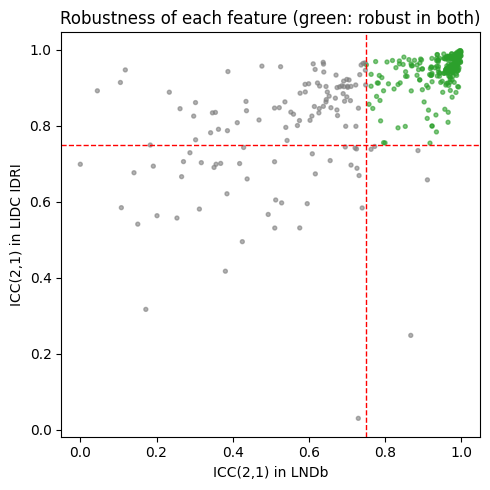

In [10]:
# Each feature as a point: its ICC in LNDb against its ICC in LIDC IDRI
colours = np.where(icc["robust"], "tab:green", "tab:grey")
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(icc["icc_LNDb"].clip(lower=-0.2), icc["icc_LIDC"].clip(lower=-0.2), s=8, alpha=0.6, c=colours)
ax.axvline(0.75, color="red", linestyle="--", linewidth=1)     # robustness threshold (Koo and Li, 2016)
ax.axhline(0.75, color="red", linestyle="--", linewidth=1)
ax.set(xlabel="ICC(2,1) in LNDb", ylabel="ICC(2,1) in LIDC IDRI", title="Robustness of each feature (green: robust in both)")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  With 211 LNDb nodules and 1843 LIDC IDRI nodules read by two radiologists, 260 of the 386 features are robust in both datasets, with a median ICC of 0.93 in LNDb and 0.94 in LIDC IDRI. LNDb is the stricter dataset: 80 features are robust only in LIDC IDRI, 5 only in LNDb, and 41 in neither. The least robust are the NGTDM features and the texture and first order features of the original image, which react to small changes of the border, together with three shape features (elongation, flatness and the ratio of surface to volume). Every size feature, both diameters included, has an ICC of at least 0.94. At 1 mm, 320 features passed this filter: at 0.6 mm more of the smallest nodules have features for both readers and enter the comparison, and their contours probably differ more between radiologists. On the same 350 nodules at every voxel size (the last section of this notebook), 0.6 mm was as robust as the larger voxels.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Keeping the features that are present, stable and not redundant
  </h3>
  <p>
  PyRadiomics gives 386 features per region, many of them unstable or near copies of each other, and with a few thousand nodules redundant inputs only add variance. Four filters are applied in this order:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Present:</strong> a feature missing in more than 20% of the regions would mostly describe the imputation.</li>
    <li style="margin-bottom: 8px;"><strong>Variable:</strong> a constant feature carries no information.</li>
    <li style="margin-bottom: 8px;"><strong>Robust:</strong> its ICC between two readers is at least 0.75 in both datasets (Koo and Li, 2016), because the model learns from both and must trust the feature in each one.</li>
    <li style="margin-bottom: 8px;"><strong>Not redundant:</strong> between two features whose absolute Spearman correlation is above 0.9, the usual cutoff in radiomics (Traverso et al., 2018), we keep the one with fewer missing values. On a tie, which is almost always the case because nearly every feature is missing only in the few regions under 8 voxels, we keep the one from the original image, which measures the nodule directly in HU and is easier to explain than a filtered version, and then the one most robust between readers (the highest ICC in its weaker dataset). The alphabetical order only breaks the last ties, so that the result is deterministic.</li>
  </ol>
  <p>
  None of these filters looks at the malignancy rating, so applying them to every nodule before the cross validation cannot leak the label into the evaluation. Every choice that does use the rating is made only inside the training folds of notebook 06 (Ambroise and McLachlan, 2002; Demircioğlu, 2021): the penalty of every model, chosen in the inner folds, shrinks the coefficients of the less useful features, and the elastic net model of notebook 06 goes further, setting them exactly to zero, which is a selection of features made inside every fit. Every removed feature is written to <strong>feature_filter_report.csv</strong> with the reason, so the selection can be audited.
  </p>
</div>

In [11]:
# What PyRadiomics gives: features per class and image type, and how many are missing or constant
consensus_rows = features[features["roi"] == "consensus"]
inventory = feature_inventory(consensus_rows, names)
missing = inventory["missing_share"]
print(f"{len(names)} features | missing in some region: {(missing > 0).sum()} (at most {missing.max():.1%} of the regions)"
      f" | constant: {inventory['constant'].sum()}")
inventory.groupby(["feature_class", "image"]).size().unstack(fill_value=0)

386 features | missing in some region: 0 (at most 0.0% of the regions) | constant: 0


image,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,original
feature_class,,,,
firstorder,18,18,18,18
glcm,24,24,24,24
gldm,14,14,14,14
glrlm,16,16,16,16
glszm,16,16,16,16
ngtdm,5,5,5,5
shape,0,0,0,14


In [12]:
# The four filters (src/mass_detect/scripts/feature_tables.py); none of them uses the rating
kept, report = label_free_filter(consensus_rows, icc, names)
print(f"kept {len(kept)} of {len(names)} features")
display(report["removed_by"].value_counts().rename("features removed").to_frame())

# The kept features by class and image, for example "glcm (original)"
families = [f"{name.split('_')[1]} ({name.split('_')[0]})" for name in kept]
pd.Series(families).value_counts().rename("kept features").to_frame()

kept 63 of 386 features


,features removed
removed_by,
redundant,197
not robust,126


,kept features
firstorder (log-sigma-3-0-mm-3D),7
firstorder (original),6
glcm (log-sigma-3-0-mm-3D),4
glcm (original),4
glszm (log-sigma-1-0-mm-3D),4
glszm (log-sigma-3-0-mm-3D),4
glszm (original),3
gldm (original),3
gldm (log-sigma-1-0-mm-3D),3
glrlm (log-sigma-3-0-mm-3D),3


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  No feature is missing in more than 20% of the regions or constant, so the first two filters remove nothing. 126 features are not robust in both datasets and 197 are near copies of a feature that is kept, which leaves 63 features. They cover every family (first order statistics, the four texture matrices, NGTDM and three shape features) on the original image and on the three LoG filters, and 21 of them come from the original image. The list of the removed features, each with its reason, is in feature_filter_report.csv.
  </p>
</div>

In [13]:
# One row per nodule (consensus region) and one row per reading (reader region), with the kept features
nodule_table, reading_table = model_tables(cohort, features, readings, kept)
without_features = int(nodule_table[kept].isna().any(axis=1).sum())
print(f"nodules: {nodule_table.shape} | readings: {reading_table.shape} | nodules without features: {without_features}")

nodules: (3237, 78) | readings: (7585, 81) | nodules without features: 0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   What the kept features say
  </h3>
  <p>
  Two questions matter before pooling the datasets. Does each feature relate to the rating in the same way in LNDb and in LIDC IDRI? And how far apart are the two datasets on each feature? The first compares the Spearman correlation of each feature with the rating in each dataset. The second uses the standardised mean difference, the difference between the two means divided by their pooled standard deviation, where 0.5 is conventionally a medium difference (Cohen, 1988).
  </p>
</div>

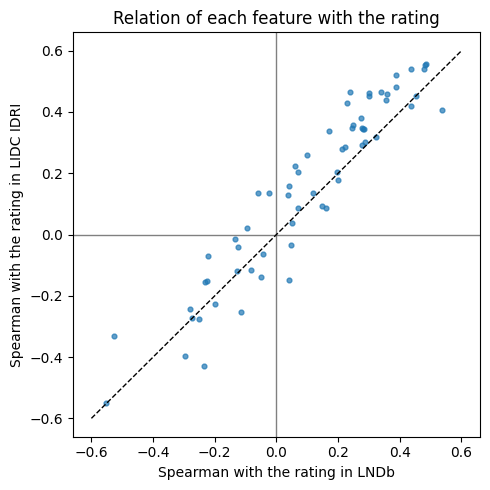

agreement between the two datasets (Spearman of the two columns): 0.95
features with the same sign in both datasets: 92%


,LIDC,LNDb,mean
original_ngtdm_Strength,-0.55,-0.55,-0.55
original_gldm_DependenceVariance,0.56,0.48,0.52
original_gldm_GrayLevelNonUniformity,0.55,0.48,0.52
log-sigma-1-0-mm-3D_gldm_DependenceVariance,0.54,0.48,0.51
log-sigma-3-0-mm-3D_glszm_LargeAreaHighGrayLevelEmphasis,0.54,0.44,0.49
original_glcm_Imc1,0.41,0.54,0.47
log-sigma-3-0-mm-3D_gldm_GrayLevelNonUniformity,0.52,0.39,0.45
original_glcm_InverseVariance,0.45,0.45,0.45
original_shape_MinorAxisLength,0.48,0.39,0.44
log-sigma-1-0-mm-3D_glcm_Imc2,-0.33,-0.53,-0.43


In [14]:
# Spearman correlation of each kept feature with the rating, in each dataset
relation = {}
for dataset, group in nodule_table.groupby("dataset"):
    relation[dataset] = group[kept].corrwith(group["rating"], method="spearman")
relation = pd.DataFrame(relation)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(relation["LNDb"], relation["LIDC"], s=12, alpha=0.7)
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(0, color="grey", linewidth=1)
ax.plot([-0.6, 0.6], [-0.6, 0.6], "k--", linewidth=1)          # the same relation in both datasets
ax.set(xlabel="Spearman with the rating in LNDb", ylabel="Spearman with the rating in LIDC IDRI",
       title="Relation of each feature with the rating")
plt.tight_layout()
plt.show()

agreement = relation["LNDb"].corr(relation["LIDC"], method="spearman")
same_sign = (np.sign(relation["LNDb"]) == np.sign(relation["LIDC"])).mean()
print(f"agreement between the two datasets (Spearman of the two columns): {agreement:.2f}")
print(f"features with the same sign in both datasets: {same_sign:.0%}")

# The ten features most related to the rating, on average over the two datasets
relation["mean"] = relation.mean(axis=1)
relation.sort_values("mean", key=abs, ascending=False).head(10).round(2)

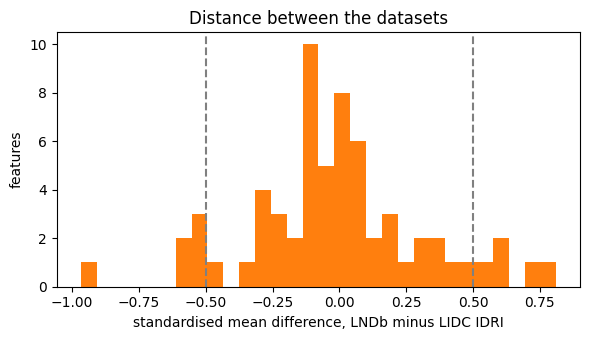

features with an absolute difference above 0.5: 11 of 63


,standardised mean difference
original_glcm_InverseVariance,-0.97
log-sigma-1-0-mm-3D_glcm_Imc2,0.81
original_firstorder_RobustMeanAbsoluteDeviation,0.73
original_ngtdm_Strength,0.62
original_glcm_DifferenceVariance,0.62


In [15]:
# How far apart the two datasets are on each kept feature: the standardised mean difference
# (the difference of the two means divided by their pooled standard deviation)
lndb_rows = nodule_table[nodule_table["dataset"] == "LNDb"]
lidc_rows = nodule_table[nodule_table["dataset"] == "LIDC"]
pooled_sd = np.sqrt((lndb_rows[kept].var() + lidc_rows[kept].var()) / 2)
difference = (lndb_rows[kept].mean() - lidc_rows[kept].mean()) / pooled_sd

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(difference, bins=30, color="tab:orange")
ax.axvline(-0.5, color="grey", linestyle="--")                  # a medium difference (Cohen, 1988)
ax.axvline(0.5, color="grey", linestyle="--")
ax.set(xlabel="standardised mean difference, LNDb minus LIDC IDRI", ylabel="features", title="Distance between the datasets")
plt.tight_layout()
plt.show()

print(f"features with an absolute difference above 0.5: {(difference.abs() > 0.5).sum()} of {len(kept)}")
difference.sort_values(key=abs, ascending=False).head(5).round(2).rename("standardised mean difference").to_frame()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The two datasets agree on what matters. The correlations of the 63 features with the rating in LNDb and in LIDC IDRI have a Spearman correlation of 0.95, and 92% of the features relate to the rating with the same sign in both. The strongest single features describe heterogeneity and size: the NGTDM strength (−0.55 in both datasets), the dependence variance and the grey level non uniformity of the GLDM (around 0.5), and the minor axis length. No feature alone comes close to the agreement between radiologists, so the combination matters. The datasets are, however, apart on some features: 11 of the 63 differ by more than half a pooled standard deviation, led by the GLCM inverse variance (−0.97). Part of this is real, since the LNDb nodules are smaller, and part is the scanner effect, which is why notebook 06 compares pooling with and without harmonisation.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The tables for the models
  </h3>
  <p>
  Notebook 06 reads two tables. <strong>model_features.csv</strong> has one row per nodule of the cohort: the kept features of its consensus region, its diameters, its label on both scales, the patient and the dataset (the groups of the cross validation), and the scanner, kernel and slice thickness (the subgroups of the fairness analysis). <strong>reading_features.csv</strong> has one row per reading: the kept features of that reader's region and that reader's rating, with a weight of 1 divided by the number of readers, so that every nodule weighs the same in total when the model is trained on single readings (Raykar et al., 2010).
  </p>
</div>

In [16]:
# The tables for notebook 06, and the report of the removed features
nodule_table.to_csv(MODEL_FEATURES_FILE, index=False)
reading_table.to_csv(READING_FEATURES_FILE, index=False)
report.to_csv(FEATURE_REPORT_FILE, index=False)
print(f"saved {MODEL_FEATURES_FILE.name} {nodule_table.shape}")
print(f"saved {READING_FEATURES_FILE.name} {reading_table.shape}")
print(f"saved {FEATURE_REPORT_FILE.name} ({len(report)} removed features)")

saved model_features.csv (3237, 78)
saved reading_features.csv (7585, 81)
saved feature_filter_report.csv (323 removed features)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Checking the Geometry of the Patch
  </h1>
  <p>
  Two numbers fix the geometry of every patch: the side of the cube (64 mm) and the size of the voxel (0.6 mm). Now that every nodule has the regions drawn by its radiologists, we check both choices on the regions the models actually use.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   How big must the cube be?
  </h3>
  <p>
  The cube must contain the whole region and also some tissue around it, because the Laplacian of Gaussian filters are computed on the whole patch before the features are read inside the region. A Gaussian kernel reaches about 3 sigma, so the widest filter (sigma 3 mm) needs about 9 mm around the region; closer to the border it sees the padding instead of the lung. For every nodule we measure the distance from the centre to the farthest voxel of its consensus region, and count, for several cube sizes, the regions that would be cut and the regions left without that margin. 30 and 32 mm are common patch sizes for small nodules, and 51 mm is the cube of the LNDb utilities (getNoduleCubes).
  </p>
</div>

In [17]:
# Cube size: how far each consensus region reaches from the centre (src/mass_detect/scripts/sensitivity.py)
extents = cube_extents(cohort)
print("consensus regions touching the border of the 64 mm cube:", extents.groupby("dataset").touches_border.sum().to_dict())
cube_fit_table(extents, sides=(30, 32, 40, 51, 64))

consensus regions touching the border of the 64 mm cube: {'LIDC': 0, 'LNDb': 0}


,cut LNDb,cut LIDC,no LoG margin LNDb,no LoG margin LIDC
30 mm,10,107,100,640
32 mm,8,84,70,464
40 mm,4,34,28,218
51 mm,1,4,8,74
64 mm,0,0,3,11


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  A 64 mm cube cuts no consensus region and no region touches its border, while 30 mm would cut 117 (10 in LNDb and 107 in LIDC IDRI), 40 mm 38 and 51 mm 5. The margin makes the difference larger still: at 30 mm, 740 regions (23% of the cohort) would have the filters running into the border, against 14 (0.4%) at 64 mm, all among the largest nodules. A bigger cube would cover these few cases but multiplies the voxels of every patch (80 mm almost doubles them), so the cube stays at 64 mm.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Which voxel size?
  </h3>
  <p>
  The IBSI asks for isotropic voxels before computing 3D texture features but does not prescribe their size therefore we decided to dive more into it. The choice pulls in two directions. A small voxel keeps the in plane detail (the median pixel is 0.64 mm in LNDb and 0.70 mm in LIDC IDRI), which matters for nodules of 3 to 5 mm, but along z it only interpolates, above all in LIDC IDRI where the median slice is 2 mm. A large voxel interpolates less but leaves small nodules with very few voxels.
  </p>
  <p>
  To decide with data, the CT and the radiologists' masks were cut again from the original scans at 0.6, 1, 1.5 and 2 mm, for every nodule of the cohort. The cube stayed at 64 mm and every PyRadiomics setting stayed the same, so only the voxel size changed. We extracted the consensus region of every nodule, plus the first two readers of every LNDb nodule read by two radiologists and of 400 random LIDC IDRI ones. The sizes are compared on four criteria, always on the same nodules:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Coverage:</strong> the share of regions that still have features, since PyRadiomics needs at least 8 voxels.</li>
    <li style="margin-bottom: 8px;"><strong>Robustness:</strong> the ICC(2,1) between two readers (Shrout and Fleiss, 1979), as above.</li>
    <li style="margin-bottom: 8px;"><strong>Dependence on the acquisition:</strong> the partial Spearman correlation between each feature and the slice thickness (LIDC IDRI) or the pixel spacing (LNDb), after removing the effect of the nodule's diameter. A feature that follows the scanner more than the nodule is a problem when the two datasets are pooled.</li>
    <li style="margin-bottom: 8px;"><strong>Prediction:</strong> the ordinal model in a nested cross validation grouped by patient (5 outer folds repeated with 3 seeds, the penalty tuned in the inner folds), on LNDb and LIDC IDRI together, scored with the mean of the QWK in each dataset. Each difference to 1 mm comes with a 95% interval from resampling whole patients (Field and Welsh, 2007).</li>
  </ol>
  <p>
  The decision rule was fixed before seeing the results: 1 mm, the slice spacing of most LNDb scans, is kept unless another size predicts better with an interval that excludes zero and is not worse on coverage and robustness.
  </p>
  <p>
  The analysis runs from the terminal with <strong>src/mass_detect/scripts/run_voxel_sensitivity.py</strong> (84 minutes with 10 processes) and saves four tables, which the cells below read. If the tables are missing, the first cell runs the analysis itself.
  </p>
</div>

In [18]:
# The tables of the voxel size analysis (src/mass_detect/scripts/run_voxel_sensitivity.py), computed here if missing
if not (RESULTS_DIR / "prediction_06_against_1mm.csv").exists():
    run_voxel_sensitivity()
coverage = pd.read_csv(RESULTS_DIR / "coverage.csv", index_col=0)
robustness = pd.read_csv(RESULTS_DIR / "robustness.csv", header=[0, 1], index_col=0)
acquisition = pd.read_csv(RESULTS_DIR / "acquisition.csv", header=[0, 1], index_col=0)
every_size = pd.read_csv(RESULTS_DIR / "prediction_every_size.csv", index_col=0)
fine_against_1mm = pd.read_csv(RESULTS_DIR / "prediction_06_against_1mm.csv", index_col=0)
coverage          # 1. share of consensus regions with features, per dataset and per nodule size

,LIDC,LNDb,under 5 mm,5 to 10 mm,10 mm or more
spacing,,,,,
0.6,1.000,1.000,1.000,1.000,1.0
1.0,0.995,1.000,0.987,1.000,1.0
1.5,0.884,0.894,0.637,0.998,1.0
2.0,0.622,0.500,0.045,0.800,1.0


In [19]:
robustness        # 2. ICC(2,1) between two readers, on the same 350 nodules at every size

nodules      median ICC        share with ICC of 0.75 or more       
dataset    LIDC LNDb       LIDC   LNDb                           LIDC   LNDb
spacing                                                                     
0.6         246  104      0.946  0.965                          0.917  0.912
1.0         246  104      0.939  0.956                          0.915  0.909
1.5         246  104      0.933  0.947                          0.896  0.870
2.0         246  104      0.916  0.909                          0.886  0.777

In [20]:
acquisition       # 3. dependence on the scanner after removing the effect of the diameter (lower is better)

median |rho|                        share with |rho| above 0.2                       
check   LIDC: slice_thickness_mm LNDb: pixel_spacing_mm   LIDC: slice_thickness_mm LNDb: pixel_spacing_mm
spacing                                                                                                  
0.6                        0.168                  0.129                      0.391                  0.060
1.0                        0.148                  0.111                      0.326                  0.028
1.5                        0.130                  0.081                      0.254                  0.000
2.0                        0.107                  0.091                      0.199                  0.000

In [21]:
# 4. Prediction: every size on the 1938 nodules that have features at every size, then 0.6 against 1 mm on almost every nodule
pd.concat({"every size": every_size, "0.6 against 1 mm": fine_against_1mm}).round(3)

QWK LIDC  QWK LNDb  mean QWK  sd over seeds  difference to 1 mm  95% interval low  95% interval high  nodules
every size       0.6     0.659     0.527     0.593          0.008               0.013            -0.011              0.033     1938
                 1.0     0.648     0.514     0.581          0.007                 NaN               NaN                NaN     1938
                 1.5     0.645     0.493     0.569          0.006              -0.013            -0.032              0.010     1938
                 2.0     0.647     0.486     0.567          0.005              -0.015            -0.042              0.009     1938
0.6 against 1 mm 0.6     0.636     0.542     0.589          0.001               0.022             0.009              0.036     3224
                 1.0     0.626     0.507     0.567          0.007                 NaN               NaN                NaN     3224

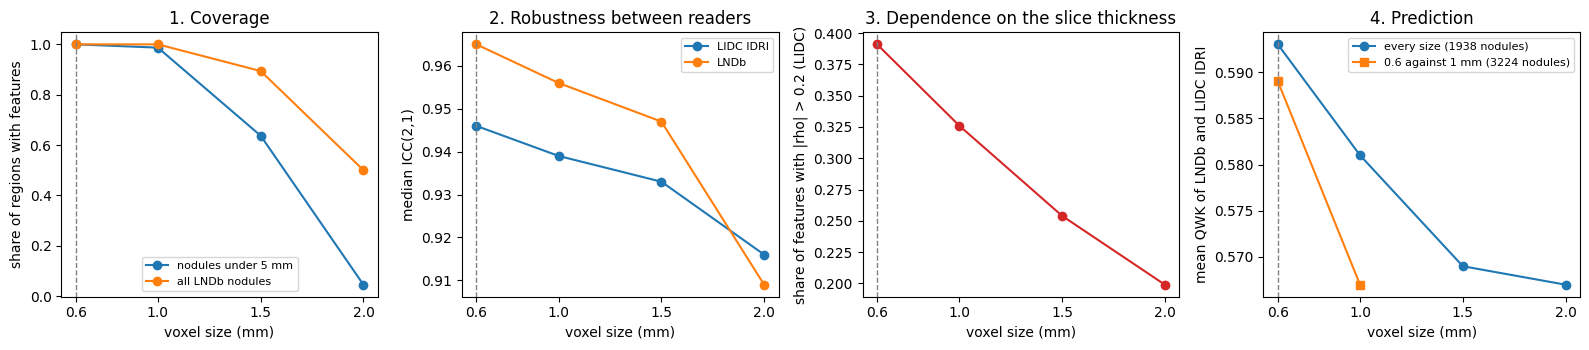

In [22]:
# The four criteria side by side; the chosen size is marked with a dashed line
sizes = coverage.index
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))

axes[0].plot(sizes, coverage["under 5 mm"], marker="o", label="nodules under 5 mm")
axes[0].plot(sizes, coverage["LNDb"], marker="o", label="all LNDb nodules")
axes[0].set(title="1. Coverage", ylabel="share of regions with features")

axes[1].plot(sizes, robustness[("median ICC", "LIDC")], marker="o", label="LIDC IDRI")
axes[1].plot(sizes, robustness[("median ICC", "LNDb")], marker="o", label="LNDb")
axes[1].set(title="2. Robustness between readers", ylabel="median ICC(2,1)")

dependence = acquisition[("share with |rho| above 0.2", "LIDC: slice_thickness_mm")]
axes[2].plot(sizes, dependence, marker="o", color="tab:red")
axes[2].set(title="3. Dependence on the slice thickness", ylabel="share of features with |rho| > 0.2 (LIDC)")

axes[3].plot(every_size.index, every_size["mean QWK"], marker="o", label=f"every size ({every_size['nodules'].iloc[0]} nodules)")
axes[3].plot(fine_against_1mm.index, fine_against_1mm["mean QWK"], marker="s",
             label=f"0.6 against 1 mm ({fine_against_1mm['nodules'].iloc[0]} nodules)")
axes[3].set(title="4. Prediction", ylabel="mean QWK of LNDb and LIDC IDRI")

for axis in axes:
    axis.axvline(0.6, color="grey", linestyle="--", linewidth=1)
    axis.set_xlabel("voxel size (mm)")
    axis.set_xticks(sizes)
    if axis.get_legend_handles_labels()[0]:
        axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Decision: 0.6 mm
  </h3>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;"><strong>Coverage rules out the large voxels.</strong> At 2 mm only 4.5% of the nodules under 5 mm keep their features, and half of the LNDb nodules lose them; at 1.5 mm a third of the small nodules are lost. At 1 mm 98.7% of the small nodules are kept, and at 0.6 mm all of them.</li>
    <li style="margin-bottom: 8px;"><strong>Robustness improves slightly as the voxel shrinks.</strong> The median ICC between two readers goes from 0.939 at 1 mm to 0.946 at 0.6 mm in LIDC IDRI, and from 0.956 to 0.965 in LNDb.</li>
    <li style="margin-bottom: 8px;"><strong>Dependence on the scanner grows as the voxel shrinks.</strong> In LIDC IDRI, 39% of the features follow the slice thickness at 0.6 mm (absolute partial correlation above 0.2), against 33% at 1 mm and 20% at 2 mm. This is the expected cost of interpolating more along z.</li>
    <li style="margin-bottom: 8px;"><strong>Prediction favours 0.6 mm.</strong> On the 3224 nodules with features at both sizes, the mean QWK is 0.589 at 0.6 mm against 0.567 at 1 mm, a difference of +0.022 (95% interval +0.009 to +0.036). The gain comes mostly from LNDb (0.542 against 0.507). On the 1938 larger nodules that have features at every size, 0.6 mm is still ahead (+0.013) but the interval includes zero, and 1.5 and 2 mm are worse than 1 mm: the extra detail matters for the small nodules.</li>
  </ol>
  <p>
  0.6 mm predicts better with an interval that excludes zero and is better on coverage and robustness, so the rule fixed in advance selects it, and every patch, mask and feature of the study is built at 0.6 mm (107 voxels per side). The stronger dependence on the slice thickness is a limitation, and it is one more reason for notebook 06 to compare harmonisation with plain pooling of the two datasets.
  </p>
</div>